# Save and reuse a Fe-Cr-Ni surrogate

Sampling is often more expensive than solving. Here we build a verified bundle
once, reload it without database calculations, and use the reloaded surrogate
in the same one-hour simulation as [the introductory notebook](fecrni_first_simulation.ipynb).

Run cells from top to bottom in the `kawin` environment with the package installed.
Start the kernel in this examples directory or at the extraction repository root.
Each notebook is independent; no earlier notebook needs to have been run.

In [1]:
from pathlib import Path
import matplotlib.pyplot as plt

from moving_boundary.mesh import CartesianFD1D, ProfileBuilder, StepProfile1D
from moving_boundary.mesh.TransformedGrids import two_phase_landau_grids
from moving_boundary.plotting import plot_composition_profiles, plot_interface_history
from moving_boundary.providers.pycalphad import create_pycalphad_thermodynamics_source
from moving_boundary.sampling import ternary_simplex_points
from moving_boundary.solvers import MovingBoundaryIllingworthTernaryFD1DModel
from moving_boundary.surrogates import TernaryMovingBoundaryThermodynamicsSurrogate
import numpy as np

## Define the couple

These are the introductory notebook's couple B inputs [1, 2]. Phases run left to
right; FE is dependent and composition pairs are `[X_CR, X_NI]` mole fractions.
Units are metres, seconds and kelvin. We model half of a symmetric FCC/BCC/FCC
couple with zero-flux outer boundaries, equal constant molar volumes and no bulk flow.
The interface has local equilibrium. The tiny position offset avoids a mesh node.

The adapted open MatCalc database [3, 4] is bundled beside these notebooks;
[the README](README.md#open-fe-cr-ni-database-and-surrogate-workflow) documents
its attribution and licence. Edit `database` if using another file location.

In [2]:
database = Path("FeCrNi_MatCalc_open.tdb")  # kernel starts beside this notebook
if not database.is_file():
    database = Path("packages/moving-boundary/examples") / database  # repository root

elements = ["FE", "CR", "NI"]
independent = ["CR", "NI"]
phases = ["BCC_A2", "FCC_A1"]
temperature = 1373.0
left_composition = [0.39696, 0.0001]   # BCC far field [2, Table 3]
right_composition = [0.139297, 0.142387]  # FCC far field [2, Table 3]

domain_length = 2000.0e-6 + 124.1e-6 / 2.0
interface_position = domain_length - 2000.0e-6 + 1.0e-12
duration = 3600.0

In [3]:
from importlib.metadata import version
from moving_boundary.surrogate_artifacts import (
    SurrogateArtifactBundle, file_sha256, load_or_build_diagnostic_surrogate,
)

## Describe the data to be saved

Use one dictionary for the sampling arguments and the compatibility specification.
The database digest, backend configuration and installed versions also identify the
data. Changing any of these settings makes the existing bundle incompatible.
The model's duration and grids do not change the sampled data and are not part of this specification.

Outputs go to an editable folder under your home directory, outside the source tree.
The example never silently replaces damaged or incompatible data. Set `rebuild=True`
in the following build cell only when you intend to replace that bundle.

In [13]:
output_dir = Path.home() / "moving_boundary_example_outputs" / "tutorials" / "fecrni_surrogate_reuse"
source_options = {"use_default_phases": False, "g_offset": 0.0}
sampling_parameters = dict(
    elements=elements, phases=phases, tieline_phases=phases, temperature=temperature,
    probe_point=[0.45, 0.21], probe_samples_per_side=8, precipitate_phase=phases[1],
    diffusivity_bulk_points=ternary_simplex_points(spacing=0.05),
    diffusivity_interpolation="simplex_positive_2x2",
    skip_failed_bulk_calculations=True, drop_invalid_bulk_matrices=True,
    validity_policy="raise", min_composition=1.0e-10,
)
build_spec = {
    "database_sha256": file_sha256(database),
    "source": {"engine": "pycalphad", "version": version("pycalphad"), **source_options},
    "package_version": version("moving-boundary"),
    "sampling": sampling_parameters,
}
report_roles = ("failed_bulk_points", "invalid_bulk_points")

## Build once, or reuse a compatible bundle

The helper calls this small builder only when data must be sampled. Creating the
source inside the builder ensures that a compatible reload does not query the
backend. The helper also saves failed/invalid-point reports alongside the surrogate.

In [14]:
def sample_surrogate(_records):
    '''Sample only on an explicit build; no backend object is needed for reload.'''
    source = create_pycalphad_thermodynamics_source(database, elements, phases, **source_options)
    return TernaryMovingBoundaryThermodynamicsSurrogate.from_database(
        thermodynamics=source, **sampling_parameters,
    )

bundle, action = load_or_build_diagnostic_surrogate(
    output_dir, build_spec, sample_surrogate, rebuild=False, report_roles=report_roles,
)
print(f"Bundle {action}; failed/invalid sampling reports are retained.")

Bundle reloaded; failed/invalid sampling reports are retained.


## Reload explicitly, including after restarting the kernel

In a **fresh kernel**, rerun the imports, physical-input and bundle-settings cells,
skip the build cell, then continue here. No earlier notebook or in-memory source is
needed. The local TDB is read only to check its digest in the settings cell.

`load` verifies the saved files and compatibility specification. It never samples
or silently repairs them. A mismatch or damaged file raises an error; inspect the
settings before deliberately rebuilding. Matching reloads establish persistence,
not surrogate accuracy. Rebuild after changing surrogate code within an editable
installation, where the version alone does not identify source edits.

In [15]:
reloaded = SurrogateArtifactBundle.load(output_dir, build_spec, required_members=report_roles)
surrogate = reloaded.surrogate
print(f"Reloaded {len(surrogate.eta_samples)} tie lines without backend calculations.")

Reloaded 17 tie lines without backend calculations.


## Build and solve the model

The physical mesh represents the initial step. Two transformed grids, with
21 and 41 nodes, follow the interface and are graded toward it. In lagged mode
bulk matrices depend on the accepted composition profile and stay fixed during
each candidate step. The surrogate also supplies the interface equilibrium.
Semi-logarithmic steps resolve startup; a thin phase raises rather than changing topology.

In [19]:
mesh = CartesianFD1D(independent, [0.0, domain_length], 61)
profile = ProfileBuilder([
    (StepProfile1D(interface_position, left_composition, right_composition), independent)
])
mesh.setResponseProfile(profile)

left_grid, right_grid = two_phase_landau_grids(
    21, 41, method="linear", spacing_ratio=0.1,
)

In [20]:
model = MovingBoundaryIllingworthTernaryFD1DModel(
    mesh=mesh,
    elements=elements,
    phases=phases,
    thermodynamics=surrogate,
    temperature=temperature,
    interfacePosition=interface_position,
    interface_equilibrium=surrogate,
    initial_eta_method="instantaneous_balance",
    initial_eta_bracket=(1.0e-3, 1.0 - 1.0e-3),
    initial_eta_guess=0.5,
    bulk_diffusivity_mode="composition_dependent_lagged",
    transformed_u_grid=left_grid,
    transformed_v_grid=right_grid,
    time_step=1.0,
    dt_mode="semi_log",
    semiLog_dt=0.05,
    semiLogT0=1.0e-6,
    tolerance=1.0e-12,
    terminal_thin_phase_width=1.0e-7,
    terminal_thin_phase_policy="raise",
    record=True,
)

`solve` advances by a duration. Rebuild the mesh and model before repeating from the initial state.

In [21]:
model.solve(duration, minDtFrac=1.0e-14, verbose=True, vIt=100)

print(f"Simulated time: {model.currentTime / 3600.0:.2f} h")
print(f"Interface position: {float(model.getInterfacePosition()) * 1.0e6:.2f} μm")

Iteration	Sim Time (h)	Run time (s)
0		0.000e+00		0.0
100		3.922e-08		1.1
200		5.820e-06		1.9
300		8.638e-04		2.8
400		1.282e-01		4.1
442		1.000e+00		4.6
Simulated time: 1.00 h
Interface position: 72.05 μm


## Inspect the simulation

Profiles are physical mole fractions, with separate curves on either side of
the sharp interface. We zoom to the first 200 micrometres of the approximately
2062 micrometre domain. The initial recorded state already imposes interface equilibrium.

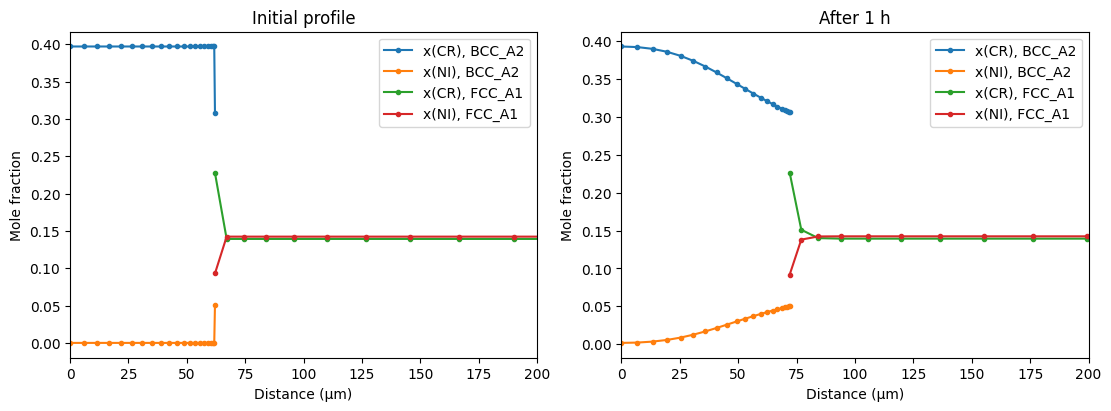

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), constrained_layout=True)
plot_composition_profiles(model, time=0.0, position_scale=1.0e6, ax=axes[0], marker='o', markersize=3)
plot_composition_profiles(model, position_scale=1.0e6, ax=axes[1], marker='o', markersize=3)
axes[0].set_title("Initial profile")
axes[1].set_title(f"After {model.currentTime / 3600.0:g} h")
for ax in axes:
    ax.set(xlim=(0, 200), xlabel="Distance (μm)", ylabel="Mole fraction")
    ax.legend()
plt.show()

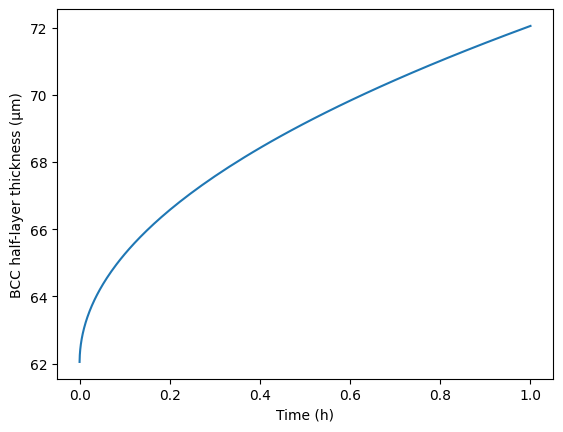

In [23]:
ax = plot_interface_history(model, time_scale=1.0 / 3600.0, position_scale=1.0e6)
ax.set(xlabel="Time (h)", ylabel="BCC half-layer thickness (μm)")
plt.show()

## Optional: check conservation

This measures the maximum component-relative inventory drift over the recorded
history. Small drift establishes conservation, not profile or surrogate accuracy.

In [24]:
from moving_boundary.analytic import recorded_history
from moving_boundary.run_diagnostics import inventory_drift

_, inventories = recorded_history(model.inventoryData)
absolute_drift, relative_drift = inventory_drift(inventories)
print(f"Maximum relative inventory drift: {relative_drift:.2e}")

Maximum relative inventory drift: 2.20e-11


Next, [assess the sampled data and predictions](fecrni_surrogate_assessment.ipynb).

## References

1. M. Kajihara, C.-B. Lim, M. Kikuchi, "Experimental study on dissolution of alpha
   phase in gamma/alpha/gamma diffusion couples of the Fe-Cr-Ni system,"
   *ISIJ International* 33 (1993) 498-507. Source of the couples and annealing temperature.
2. B.-J. Lee, K. H. Oh, "Numerical treatment of the moving interface in diffusional
   reactions," *Z. Metallkd.* 87 (1996) 195-204. Couple B compositions and dimensions
   from Table 3, originating in [1].
3. E. Povoden-Karadeniz, MatCalc thermodynamic steel database mc_fe, release 2.060,
   TU Wien, [MatCalc open databases](https://www.matcalc.at/index.php/databases/open-databases).
   Thermodynamic parameters in the bundled adapted excerpt; ODbL 1.0 / DbCL 1.0.
4. E. Povoden-Karadeniz, MatCalc diffusion mobility database for steel (mc_fe), TU Wien,
   same source and licence as [3]. Mobility parameters in the excerpt match releases
   2.012, 2.015, and 2.016; no single release is identified.